[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L1/BA_L1_logscale/BA_L1_logscale.ipynb)

# BA_L1_logscale: One Series on a Linear and a Log Scale

*Quantlet of Lecture 1, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Bitcoin market value, monthly means, November 2014 to October 2025, on a linear and on a log scale; with a worked example showing that log returns add up over time and simple returns do not.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))

## Data and method

Monthly means of Bitcoin's market value (USD bn), with the 11 days of recording error (27 August to 6 September 2023)
removed. On a log scale equal distances are equal ratios: 10, 100 and 1 000 USD bn are equally spaced.

**How to read the chart.** Left: on a linear scale the first years are a flat line near zero. Right: on a log scale
every tenfold rise has the same height, and the early growth and the falls of 2018 and 2022 become visible.

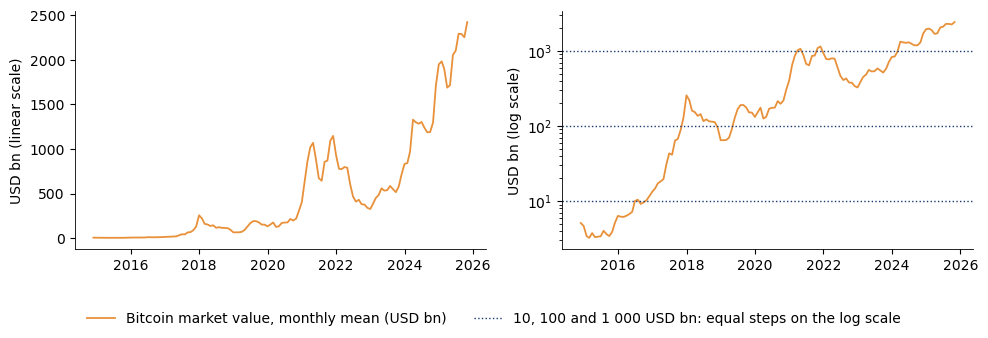

132 months, Nov 2014 - Oct 2025; maximum 2,421 USD bn (Oct 2025)
January 2015: 3.4 USD bn = 0.14% of the maximum
December 2017: 256 USD bn; December 2018: 65 USD bn
Months below 10% of the maximum: 54% of the sample


In [5]:
# Bitcoin market value (monthly mean, recording error removed) on a linear and on a log scale
mc_btc = load_onchain('Mktcap')['BTC']
mc_btc.loc['2023-08-27':'2023-09-06'] = np.nan
mv_month = (mc_btc.resample('ME').mean() / 1e9).dropna()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a_, scale in zip(ax, ['linear', 'log']):
    a_.plot(mv_month.index, mv_month, color=BTC, lw=1.3, label=('Bitcoin market value, monthly mean (USD bn)' if scale == 'linear' else None))
    a_.set_yscale(scale); a_.set_ylabel(f'USD bn ({scale} scale)')
ax[1].axhline(10, color=BLUE, ls=':', lw=1); ax[1].axhline(100, color=BLUE, ls=':', lw=1)
ax[1].axhline(1000, color=BLUE, ls=':', lw=1, label='10, 100 and 1 000 USD bn: equal steps on the log scale')
legend_below(fig, ncol=2, bottom=0.14)
save_fig(fig, 'ba_l1_logscale')

top_ = mv_month.max()
print(f'{len(mv_month)} months, {mv_month.index[0]:%b %Y} - {mv_month.index[-1]:%b %Y}; maximum {top_:,.0f} USD bn ({mv_month.idxmax():%b %Y})')
print(f'January 2015: {mv_month.loc["2015-01"].iloc[0]:.1f} USD bn = {100 * mv_month.loc["2015-01"].iloc[0] / top_:.2f}% of the maximum')
print(f'December 2017: {mv_month.loc["2017-12"].iloc[0]:,.0f} USD bn; December 2018: {mv_month.loc["2018-12"].iloc[0]:,.0f} USD bn')
print(f'Months below 10% of the maximum: {100 * (mv_month < 0.1 * top_).mean():.0f}% of the sample')

Simple returns and log returns over three dates: only log returns add up.

In [6]:
# worked example: simple and log returns over three dates (monthly means of the market value)
pts = [mv_month.loc[d].iloc[0] for d in ['2017-12', '2018-12', '2020-12']]
r1, r2 = pts[1] / pts[0] - 1, pts[2] / pts[1] - 1
l1, l2 = np.log(pts[1] / pts[0]), np.log(pts[2] / pts[1])
print('Market value (USD bn), monthly means: Dec 2017 {:,.1f}, Dec 2018 {:,.1f}, Dec 2020 {:,.1f}'.format(*pts))
print(f'Simple returns: {100 * r1:.1f}% and {100 * r2:+.1f}%; their sum {100 * (r1 + r2):+.1f}%; '
      f'the two-year simple return {100 * (pts[2] / pts[0] - 1):+.1f}%')
print(f'Log returns: {l1:.3f} and {l2:+.3f}; their sum {l1 + l2:+.3f} = ln({pts[2]:,.1f} / {pts[0]:,.1f}) = {np.log(pts[2] / pts[0]):+.3f}')
print(f'Back to a simple return: exp({l1 + l2:.3f}) - 1 = {100 * (np.exp(l1 + l2) - 1):+.1f}%')

Market value (USD bn), monthly means: Dec 2017 256.1, Dec 2018 64.8, Dec 2020 403.1
Simple returns: -74.7% and +522.2%; their sum +447.5%; the two-year simple return +57.4%
Log returns: -1.375 and +1.828; their sum +0.454 = ln(403.1 / 256.1) = +0.454
Back to a simple return: exp(0.454) - 1 = +57.4%
